# **WEEK 11-12 hack-o-week**

Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

sns.set_theme(style="whitegrid")
print("Libraries loaded ✅")

Libraries loaded ✅


LOAD DATASET

Shape: (1797, 64) -> 1797 samples, 64 features (dimensions)


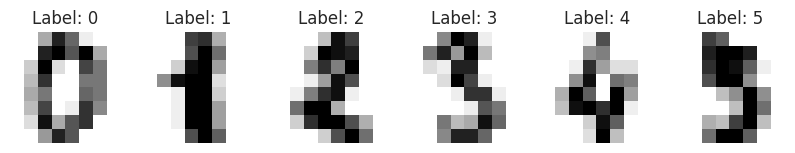

In [3]:
# Using sklearn's built-in Digits dataset - real data of 1,797 handwritten digit images (0-9), where each image is
# 8x8 pixels = 64 features. Perfect for dimensionality reduction since 64 dimensions can't be visualized directly.
digits = load_digits()
X = digits.data
y = digits.target
print("Shape:", X.shape, "-> 1797 samples, 64 features (dimensions)")

# Quick look at a few images
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for i, ax in enumerate(axes):
    ax.imshow(digits.images[i], cmap='gray_r')
    ax.set_title(f"Label: {y[i]}")
    ax.axis('off')
plt.show()


SCALING (Pre-requisite)

In [4]:
# Feature Scaling - PCA is sensitive to the scale of features (it looks at variance), so we standardize
# all features to mean 0 and std 1 first so no single feature dominates just because of larger numbers.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

PCA (Principal Component Analysis)

Original shape: (1797, 64) -> After PCA: (1797, 2)
Explained variance ratio (PC1, PC2): [0.12  0.096]
Total variance captured by 2 components: 21.59 %


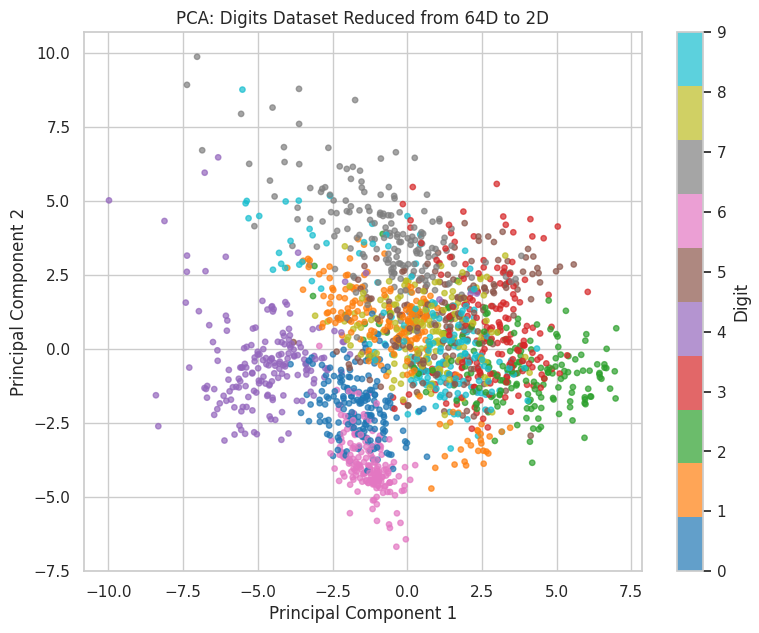

In [5]:
# PCA (Principal Component Analysis) - a technique that reduces many features into a few new "principal components"
# (new axes) that capture the maximum variation/information in the data. Intuition: it finds the directions along
# which the data is most spread out, and projects the data onto those, using eigenvectors/eigenvalues of the
# covariance matrix (the same linear algebra concept from Week 5-6).
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape, "-> After PCA:", X_pca_2d.shape)

# Explained Variance Ratio - tells how much of the total information (variance) each principal component captures.
print("Explained variance ratio (PC1, PC2):", np.round(pca_2d.explained_variance_ratio_, 3))
print("Total variance captured by 2 components:", round(pca_2d.explained_variance_ratio_.sum() * 100, 2), "%")

# Visualizing 64-dimensional data in just 2 dimensions
plt.figure(figsize=(9, 7))
scatter = plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y, cmap='tab10', alpha=0.7, s=15)
plt.colorbar(scatter, label='Digit')
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Digits Dataset Reduced from 64D to 2D")
plt.show()

PCA - Choosing Number of Components (Scree Plot / Cumulative Variance)

Components needed to retain 95% variance: 40 out of 64


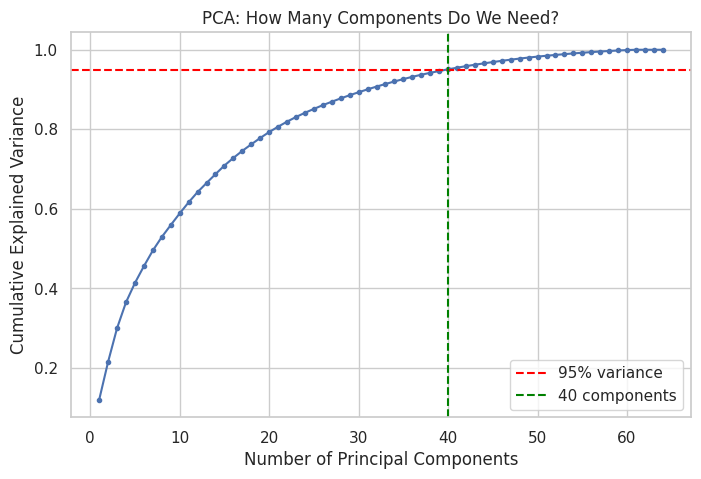

In [6]:
# Cumulative Explained Variance - shows how much total information is retained as we keep more components;
# helps decide how many components are enough (commonly the point where ~95% variance is preserved).
pca_full = PCA()
pca_full.fit(X_scaled)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1
print("Components needed to retain 95% variance:", n_components_95, "out of 64")

plt.figure(figsize=(8, 5))
plt.plot(range(1, 65), cumulative_variance, marker='o', markersize=3)
plt.axhline(y=0.95, color='red', linestyle='--', label='95% variance')
plt.axvline(x=n_components_95, color='green', linestyle='--', label=f'{n_components_95} components')
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA: How Many Components Do We Need?")
plt.legend()
plt.show()

PCA - Application 1: Image Compression / Reconstruction

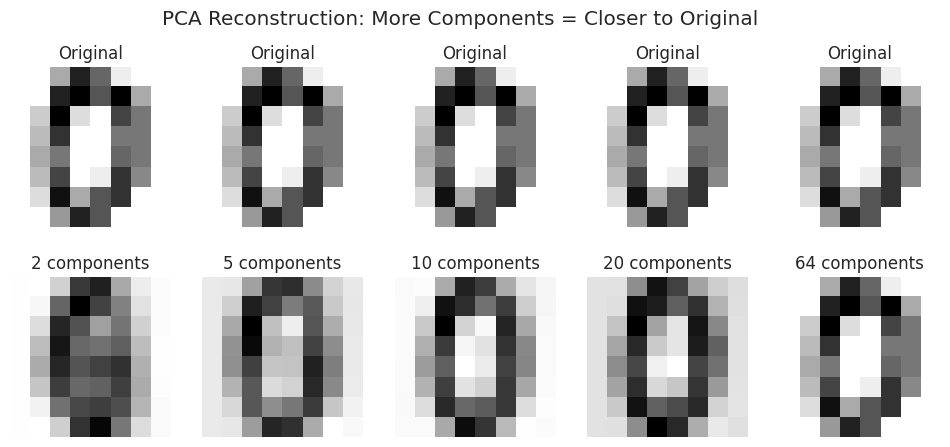

In [7]:
# Reconstruction - PCA can compress data and rebuild an approximation from fewer components; the more components
# kept, the closer the reconstructed image is to the original (a practical use of PCA: compression/denoising).
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
component_counts = [2, 5, 10, 20, 64]

for i, n in enumerate(component_counts):
    pca_temp = PCA(n_components=n)
    X_reduced = pca_temp.fit_transform(X_scaled)
    X_reconstructed = pca_temp.inverse_transform(X_reduced)
    X_reconstructed_original_scale = scaler.inverse_transform(X_reconstructed)

    axes[0, i].imshow(digits.images[0], cmap='gray_r')
    axes[0, i].set_title("Original")
    axes[0, i].axis('off')

    axes[1, i].imshow(X_reconstructed_original_scale[0].reshape(8, 8), cmap='gray_r')
    axes[1, i].set_title(f"{n} components")
    axes[1, i].axis('off')

plt.suptitle("PCA Reconstruction: More Components = Closer to Original")
plt.show()


PCA - Application 2: Faster Model Training with Fewer Features

In [8]:
# Using PCA before a model - reducing features speeds up training and can reduce overfitting, while keeping
# most of the useful information; here we compare a model on all 64 features vs PCA-reduced features.
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)

model_full = LogisticRegression(max_iter=5000)
model_full.fit(X_train, y_train)
acc_full = accuracy_score(y_test, model_full.predict(X_test))

pca_model = PCA(n_components=n_components_95)
X_train_pca = pca_model.fit_transform(X_train)
X_test_pca = pca_model.transform(X_test)

model_pca = LogisticRegression(max_iter=5000)
model_pca.fit(X_train_pca, y_train)
acc_pca = accuracy_score(y_test, model_pca.predict(X_test_pca))

print(f"Accuracy with all 64 features: {acc_full:.3f}")
print(f"Accuracy with {n_components_95} PCA components: {acc_pca:.3f}")

Accuracy with all 64 features: 0.972
Accuracy with 40 PCA components: 0.953


 t-SNE (Intuition)

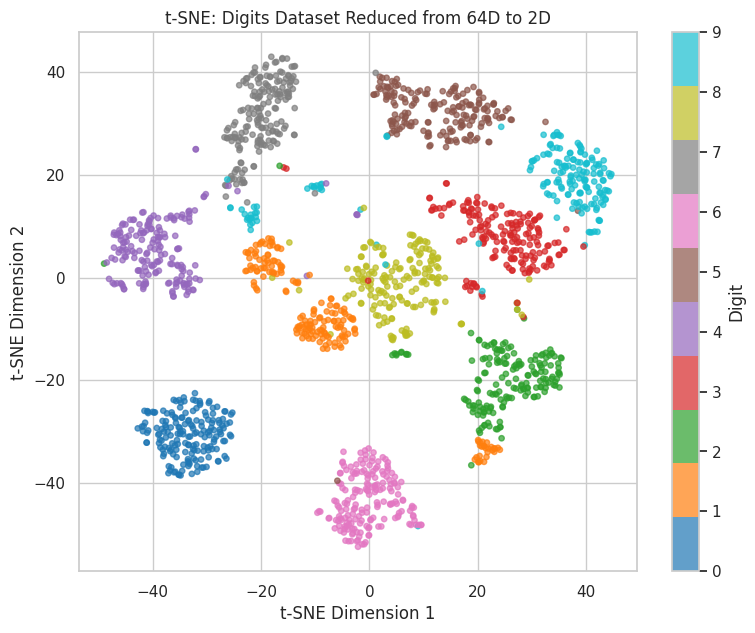

In [9]:
# t-SNE (t-distributed Stochastic Neighbor Embedding) - a technique mainly used for VISUALIZING high-dimensional
# data in 2D/3D. Intuition: it tries to keep points that are close neighbors in the original high-dimensional
# space close together in the low-dimensional map, and pushes dissimilar points apart, which reveals natural
# clusters/groups very clearly.
tsne = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto', random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(9, 7))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap='tab10', alpha=0.7, s=15)
plt.colorbar(scatter, label='Digit')
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.title("t-SNE: Digits Dataset Reduced from 64D to 2D")
plt.show()


t-SNE - Effect of Perplexity

In [ ]:
# Perplexity - the main t-SNE setting; roughly means "how many close neighbors each point considers" - low values
# focus on very local structure, high values capture broader/global structure (typical range: 5 to 50).
perplexities = [5, 30, 50]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, perp in zip(axes, perplexities):
    tsne_temp = TSNE(n_components=2, perplexity=perp, init='pca', learning_rate='auto', random_state=42)
    X_temp = tsne_temp.fit_transform(X_scaled)
    ax.scatter(X_temp[:, 0], X_temp[:, 1], c=y, cmap='tab10', alpha=0.7, s=10)
    ax.set_title(f"t-SNE (perplexity={perp})")

plt.tight_layout()
plt.show()

PCA vs t-SNE (Side-by-Side Comparison)

In [ ]:
# PCA vs t-SNE - PCA is a LINEAR, fast method that preserves global structure and can be reused on new data;
# t-SNE is a NON-LINEAR, slower method that preserves local neighborhoods and gives better cluster visualization,
# but is meant only for visualization (distances between far-apart clusters aren't meaningful).
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sc1 = axes[0].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y, cmap='tab10', alpha=0.7, s=12)
axes[0].set_title("PCA (Linear) - Clusters overlap more")
axes[0].set_xlabel("PC 1")
axes[0].set_ylabel("PC 2")

sc2 = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap='tab10', alpha=0.7, s=12)
axes[1].set_title("t-SNE (Non-linear) - Clusters clearly separated")
axes[1].set_xlabel("t-SNE 1")
axes[1].set_ylabel("t-SNE 2")

fig.colorbar(sc2, ax=axes, label='Digit')
plt.show()

In [ ]:
print("\n Week 11-12 demo complete — Dimensionality Reduction (PCA & t-SNE) covered with intuition, visualization, and applications!")
